# Классификация качества кофе: логистическая регрессия

Та же схема, что в ноутбуке про рак груди, но на новых данных (`archive.zip`, датасет про партии зелёного кофе).

**План**
1. Загрузка и очистка данных (дубликаты)
2. Целевая переменная и выбор признаков (без утечек)
3. Разбиение на train / test
4. **Обработка пропусков**
5. **Обработка категориальных переменных**
6. **Логистическая регрессия**
7. **Метрики**: accuracy, precision, recall, F1, confusion matrix, ROC

**Задача:** по характеристикам партии (ферма, климат, обработка, хранение, физические параметры зерна) предсказать `quality_grade`, один из 5 классов:
`Commercial < Good < Very Good < Excellent < Exceptional`.
В образце классов было 2 (рак / нет рака), здесь их 5. Это многоклассовая классификация, и метрики усредняются по классам.

In [1]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, roc_auc_score)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)

## 1. Загрузка данных

В архиве 4 файла:
- `coffee_value_benchmark.csv`: основная таблица (одна строка = одна запись о партии);
- `feature_dictionary.csv`: описание столбцов и **какие из них можно использовать как признаки для качества**;
- `coffee_benchmark_splits.csv`: готовое разбиение партий на Train и Test (по времени);
- `coffee_record_metadata.csv`: тип записи (оригинал, дубликат, ревизия измерений).

> Важная деталь. В столбце `certification` значение `"None"` означает «сертификата нет». Но pandas по умолчанию читает строку `"None"` как пропуск (NaN). Поэтому читаем с `keep_default_na=False`, чтобы настоящие пропуски остались только пустыми ячейками.

In [2]:
ZIP_PATH = 'archive.zip'   # положите архив рядом с ноутбуком (или поправьте путь)
z = zipfile.ZipFile(ZIP_PATH)

def read(name, **kw):
    with z.open(name) as f:
        return pd.read_csv(f, **kw)

# "None" в certification -- это категория, а не пропуск; пустые ячейки остаются NaN
df = read('coffee_value_benchmark.csv', keep_default_na=False, na_values=[''])
meta = read('coffee_record_metadata.csv')
splits = read('coffee_benchmark_splits.csv')
fdict = read('feature_dictionary.csv')

df.shape, meta.shape, splits.shape

((35700, 36), (35700, 3), (35000, 2))

In [3]:
df.head()

     record_id       lot_id harvest_season  harvest_calendar_year  harvest_month country_of_origin    farm_type  farm_size_hectares  tree_age_years  altitude_mean_meters  species  avg_temp_c  \
0  REC-0000001  LOT-0032936        2020/21                   2020             10           Vietnam  Smallholder                0.58            28.0                1961.0  Arabica        16.9   
1  REC-0000002  LOT-0030952        2021/22                   2022              1          Honduras  Smallholder                1.12             2.0                1257.0  Arabica        16.5   
2  REC-0000003  LOT-0018572        2020/21                   2020             11           Vietnam  Cooperative               13.82             5.0                 557.0  Robusta        23.3   
3  REC-0000004  LOT-0005318        2021/22                   2021             10           Vietnam  Cooperative                9.96            22.0                 652.0  Robusta        24.6   
4  REC-0000005  LOT-0006317   

## 2. Дубликаты и ревизии

Строк в таблице 35 700, а уникальных партий (`lot_id`) 35 000. Смотрим на тип записи.

In [4]:
data = df.merge(meta[['record_id', 'record_type']], on='record_id').merge(splits, on='lot_id')
print(data.record_type.value_counts())
print('\nПартий с несколькими записями:', (data.groupby('lot_id').size() > 1).sum())

record_type
Original                35000
Measurement Revision      350
Exact Duplicate           350
Name: count, dtype: int64

Партий с несколькими записями: 695

Есть 350 точных дубликатов и 350 «ревизий измерений», это повторные записи тех же партий. Если их оставить, одна и та же партия может попасть и в обучение, и в оценку, а метрики станут чуть красивее, чем есть на самом деле. Оставляем только `Original`, по одной строке на партию.

In [5]:
data = data[data.record_type == 'Original'].copy()
print(data.shape, '| уникальных партий:', data.lot_id.nunique())

(35000, 38) | уникальных партий: 35000

## 3. Целевая переменная и признаки

Целевая переменная: `quality_grade`. Классы упорядочены, поэтому закодируем их числами 0..4 в естественном порядке.

**Какие признаки брать.** В `feature_dictionary.csv` для каждого столбца указано, можно ли его использовать для предсказания качества. Нельзя использовать:
- `coffee_quality_score` и оценки вкуса (`acidity_score`, `body_score`, ...): `quality_grade` буквально получена из `coffee_quality_score` по квантилям, это утечка целевой переменной;
- `price_usd_per_kg`: тоже результат, а не причина;
- коммерческие поля и `roast_level` помечены как недоступные для задачи качества;
- `record_id`, `lot_id`: идентификаторы.

Берём только столбцы с `usable_as_feature_for_quality = True`.

In [6]:
feats = fdict.loc[fdict.usable_as_feature_for_quality, 'column'].tolist()
print(len(feats), 'признаков:\n', feats)

# целевая переменная: упорядоченные классы -> числа 0..4
order = ['Commercial', 'Good', 'Very Good', 'Excellent', 'Exceptional']
data['y'] = pd.Categorical(data.quality_grade, categories=order, ordered=True).codes

data.quality_grade.value_counts().reindex(order)

21 признаков:
 ['harvest_season', 'harvest_calendar_year', 'harvest_month', 'country_of_origin', 'farm_type', 'farm_size_hectares', 'tree_age_years', 'altitude_mean_meters', 'species', 'avg_temp_c', 'avg_annual_rainfall_mm', 'humidity_pct', 'processing_method', 'drying_method', 'drying_duration_days', 'storage_months', 'storage_conditions', 'bean_size_screen', 'moisture_pct', 'bean_density_g_ml', 'defect_rate_pct']

quality_grade
Commercial      7000
Good            7000
Very Good      12250
Excellent       7000
Exceptional     1750
Name: count, dtype: int64

## 4. Разбиение на train / test

В образце использовался случайный `train_test_split`. Здесь авторы датасета дали готовое **временное** разбиение: обучаемся на ранних урожаях, проверяем на поздних (как в реальности, когда модель предсказывает будущее). Используем его.

Перед этим уберём два признака, которые «привязывают» объект ко времени: `harvest_calendar_year` и `harvest_season`. В тесте есть сезон `2023/24`, которого нет в обучении, и модели не на чем научиться его трактовать. Месяц урожая (`harvest_month`) оставляем.

In [7]:
drop_time = ['harvest_calendar_year', 'harvest_season']
feats = [c for c in feats if c not in drop_time]

train = data[data.temporal_split == 'Train']
test  = data[data.temporal_split != 'Train']

X_train, y_train = train[feats], train.y
X_test,  y_test  = test[feats],  test.y

print('train:', X_train.shape, '| test:', X_test.shape)

train: (29638, 19) | test: (5362, 19)

## 5. Обработка пропусков

Смотрим, где в признаках есть пропуски (по обучающей выборке).

In [8]:
miss = X_train.isna().sum()
miss = miss[miss > 0].to_frame('пропусков')
miss['доля, %'] = (miss['пропусков'] / len(X_train) * 100).round(1)
miss

                        пропусков  доля, %
avg_annual_rainfall_mm       1488      5.0
humidity_pct                 1889      6.4
moisture_pct                 1587      5.4
bean_density_g_ml            1607      5.4

Пропуски есть в 4 числовых столбцах, по ~5% в каждом. Что с ними делать:

- **Удалить строки с пропусками**: теряем много данных. Посмотрим сколько.
- **Заполнить** (impute): медианой, средним, чем-то более умным.

In [9]:
n_full = X_train.dropna().shape[0]
print(f'Строк без единого пропуска: {n_full} из {len(X_train)} '
      f'(потеряли бы {100 - n_full / len(X_train) * 100:.0f}% обучающей выборки)')

Строк без единого пропуска: 23770 из 29638 (потеряли бы 20% обучающей выборки)

Удалять строки слишком дорого, поэтому **заполняем медианой** (устойчива к выбросам). Важно считать медиану **только по train** и этой же цифрой заполнять test, иначе информация из теста «просочится» в обучение. Для этого используем `SimpleImputer` внутри `Pipeline`: он запоминает медианы на `fit` и применяет их на `transform`.

(Замечание: в тесте столбцы `moisture_pct` и `bean_density_g_ml` вообще без пропусков, а в train они есть. Заполнение по train с этим справляется без проблем.)

In [10]:
print('Пропуски в test:'); print(X_test.isna().sum()[lambda s: s > 0])

Пропуски в test:
avg_annual_rainfall_mm    289
humidity_pct              350
dtype: int64

## 6. Обработка категориальных переменных

Логистическая регрессия работает только с числами. Категориальные столбцы (страна, тип фермы, метод обработки и т. д.) не имеют порядка (`Brazil` не «больше» `Kenya`), поэтому кодируем их **one-hot**: на каждую категорию отдельный столбец из 0 и 1. Параметр `handle_unknown='ignore'` нужен, чтобы модель не падала, если в тесте встретится категория, которой не было в обучении.

Числовые признаки дополнительно **масштабируем** (`StandardScaler`): у них очень разные масштабы (площадь фермы в гектарах, высота в метрах, влажность в процентах), а логистическая регрессия с регуляризацией чувствительна к масштабу.

In [11]:
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()
num_cols = X_train.select_dtypes(include='number').columns.tolist()
print('Категориальные:', cat_cols)
print('Числовые:', num_cols)

Категориальные: ['country_of_origin', 'farm_type', 'species', 'processing_method', 'drying_method', 'storage_conditions']
Числовые: ['harvest_month', 'farm_size_hectares', 'tree_age_years', 'altitude_mean_meters', 'avg_temp_c', 'avg_annual_rainfall_mm', 'humidity_pct', 'drying_duration_days', 'storage_months', 'bean_size_screen', 'moisture_pct', 'bean_density_g_ml', 'defect_rate_pct']

In [12]:
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),   # пропуски -> медиана по train
    ('scale',  StandardScaler()),                   # приводим к одному масштабу
])

preprocess = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

# посмотрим, что получилось после преобразования
Xt = preprocess.fit_transform(X_train)
print('Было признаков:', X_train.shape[1], '-> стало:', Xt.shape[1])
print('Пропусков после обработки:', int(np.isnan(Xt).sum()))

Было признаков: 19 -> стало: 34
Пропусков после обработки: 0

## 7. Логистическая регрессия

Собираем всё в один `Pipeline`: предобработка + модель. Так при `predict` на новых данных автоматически применяются те же медианы, масштаб и кодирование, что были на обучении.

Для 5 классов `LogisticRegression` обучает многоклассовую (softmax) модель. Для сравнения сначала посчитаем **бейзлайн**: модель, которая всегда предсказывает самый частый класс. Любая осмысленная модель должна его побить.

In [13]:
model = Pipeline([
    ('prep', preprocess),
    ('clf',  LogisticRegression(max_iter=2000)),
])
model.fit(X_train, y_train)

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print('Accuracy бейзлайна (всегда "Very Good"):', round(accuracy_score(y_test, baseline.predict(X_test)), 3))

Accuracy бейзлайна (всегда "Very Good"): 0.355

## 8. Метрики

Для многоклассовой задачи precision / recall / F1 считаем для каждого класса отдельно, а затем усредняем:
- `macro`: простое среднее по классам (все классы одинаково важны, даже редкий `Exceptional`);
- `weighted`: среднее с весами по размеру классов.

In [14]:
y_pred = model.predict(X_test)

print('accuracy        :', round(accuracy_score(y_test, y_pred), 3))
print('precision (macro):', round(precision_score(y_test, y_pred, average='macro'), 3))
print('recall    (macro):', round(recall_score(y_test, y_pred, average='macro'), 3))
print('f1        (macro):', round(f1_score(y_test, y_pred, average='macro'), 3))

print('\nAccuracy на train:', round(accuracy_score(y_train, model.predict(X_train)), 3),
      '| на test:', round(accuracy_score(y_test, y_pred), 3), '(близко: переобучения нет)')

accuracy        : 0.706
precision (macro): 0.709
recall    (macro): 0.658
f1        (macro): 0.674

Accuracy на train: 0.687 | на test: 0.706 (близко: переобучения нет)

In [15]:
print(classification_report(y_test, y_pred, target_names=order, digits=3))

              precision    recall  f1-score   support

  Commercial      0.779     0.877     0.825      1055
        Good      0.658     0.512     0.576      1069
   Very Good      0.713     0.776     0.743      1902
   Excellent      0.642     0.664     0.653      1078
 Exceptional      0.753     0.461     0.572       258

    accuracy                          0.706      5362
   macro avg      0.709     0.658     0.674      5362
weighted avg      0.703     0.706     0.700      5362

### Confusion matrix

Строки: настоящий класс, столбцы: предсказанный. На диагонали верные ответы.

             Commercial  Good  Very Good  Excellent  Exceptional
Commercial          925   126          4          0            0
Good                260   547        260          2            0
Very Good             3   158       1476        265            0
Excellent             0     0        323        716           39
Exceptional           0     0          7        132          119
Доля ответов, отличающихся от истинного класса не более чем на 1 ступень: 0.997

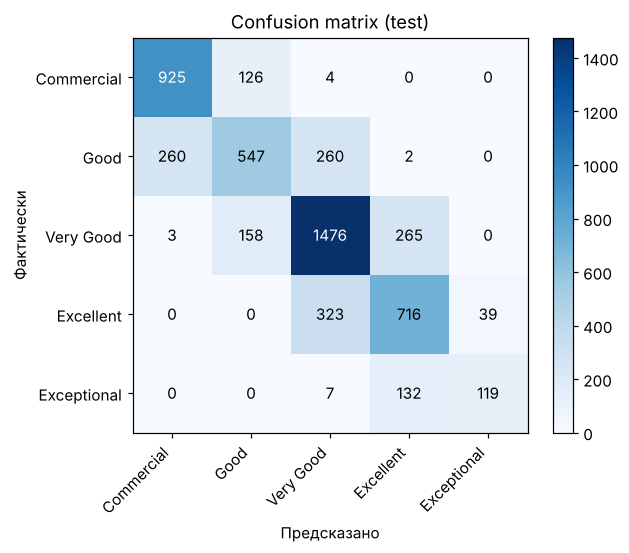

In [16]:
cm = confusion_matrix(y_test, y_pred)
print(pd.DataFrame(cm, index=order, columns=order))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(5)); ax.set_xticklabels(order, rotation=45, ha='right')
ax.set_yticks(range(5)); ax.set_yticklabels(order)
for i in range(5):
    for j in range(5):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xlabel('Предсказано'); ax.set_ylabel('Фактически')
ax.set_title('Confusion matrix (test)')
plt.colorbar(im); plt.tight_layout(); plt.show()

print('Доля ответов, отличающихся от истинного класса не более чем на 1 ступень:',
      round((abs(y_test - y_pred) <= 1).mean(), 3))

### ROC-кривые

Для 5 классов строим ROC по схеме «один класс против остальных» (one-vs-rest). Важно: для ROC нужны **вероятности** (`predict_proba`), а не предсказанные метки. В образце использовались метки `Y_predicted`, из-за чего кривая получалась ломаной всего из трёх точек. С вероятностями кривая получается настоящей.

ROC-AUC (macro, one-vs-rest): 0.928

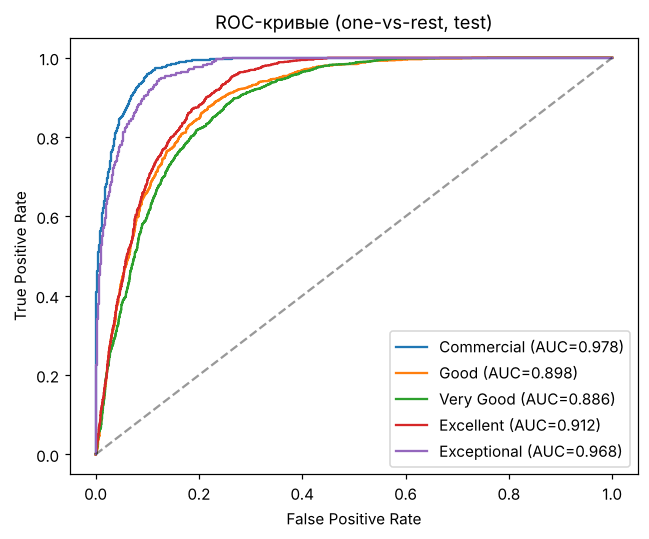

In [17]:
proba = model.predict_proba(X_test)

plt.figure(figsize=(6, 5))
for k, name in enumerate(order):
    fpr, tpr, _ = roc_curve((y_test == k).astype(int), proba[:, k])
    auc_k = roc_auc_score((y_test == k).astype(int), proba[:, k])
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc_k:.3f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC-кривые (one-vs-rest, test)'); plt.legend(); plt.tight_layout(); plt.show()

print('ROC-AUC (macro, one-vs-rest):', round(roc_auc_score(y_test, proba, multi_class='ovr', average='macro'), 3))

## Выводы

- **Данные.** Убрали 700 повторных записей, исключили признаки-утечки (оценки вкуса, итоговый балл, цена) и использовали готовое временное разбиение.
- **Пропуски.** ~5% в четырёх числовых столбцах. Удаление строк стоило бы ~20% обучающей выборки, поэтому заполнили медианой (по train). Отдельно: `"None"` в `certification` не пропуск, а категория.
- **Категориальные.** One-hot кодирование + масштабирование числовых признаков внутри одного `Pipeline`.
- **Результат.** Логистическая регрессия даёт accuracy ≈ 0.71 против 0.35 у бейзлайна, macro-F1 ≈ 0.67, ROC-AUC ≈ 0.93. Переобучения нет: на train и test accuracy почти одинаковая (0.69 и 0.71). Почти все ошибки приходятся на соседние классы (99.7% ответов отличаются от истины не более чем на одну ступень), что для упорядоченных оценок качества логично.
- **Сильное место:** `Commercial` (F1 ≈ 0.83) и самый крупный класс `Very Good`.
- **Слабые места:** у `Good` recall ≈ 0.51 (путается с `Commercial` и `Very Good`), у `Exceptional` recall ≈ 0.46 (почти все пропуски уходят в `Excellent`). Точность по `Exceptional` высокая (≈ 0.75), но модель слишком осторожна и редко его называет. Редкий класс (5% данных) можно улучшить, например, через `class_weight='balanced'`.